# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
from aitlas.datasets import SSDDDataset 
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 1160


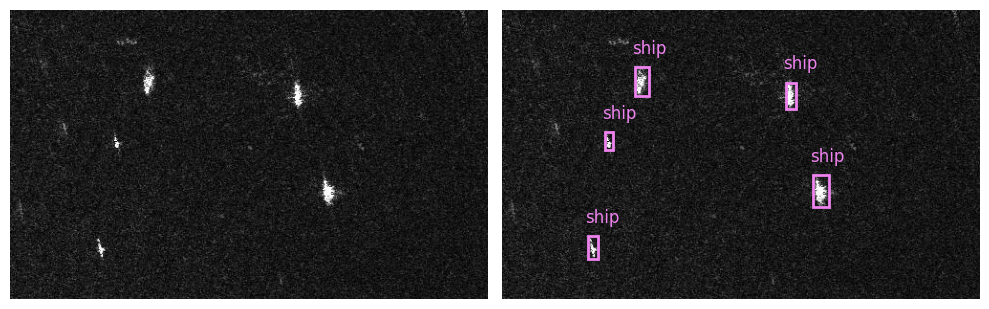

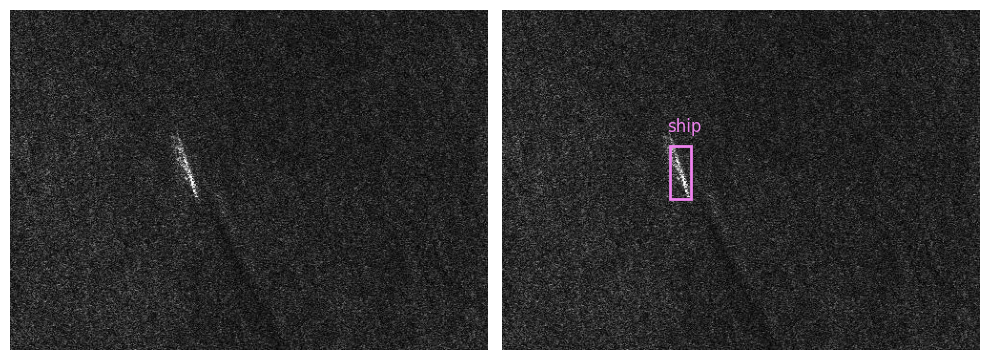

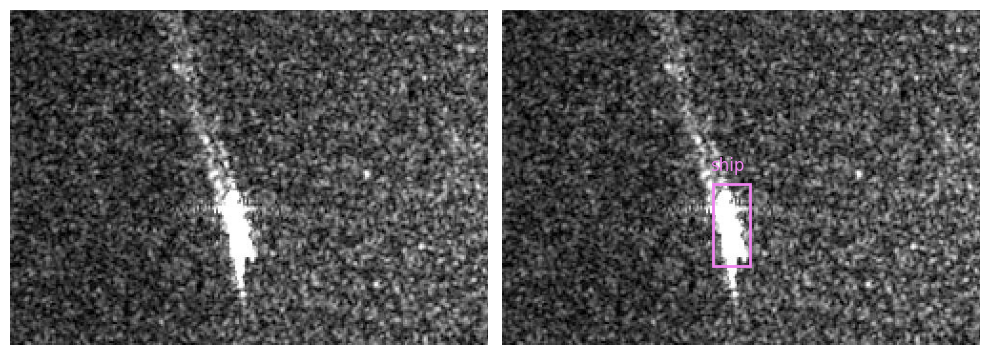

In [17]:
dataset_config = {
    "image_dir": "/home/dragik/data/FAIR_EO/SSDD/JPEGImages/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/SSDD/Annotations/",
}
dataset = SSDDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(100);

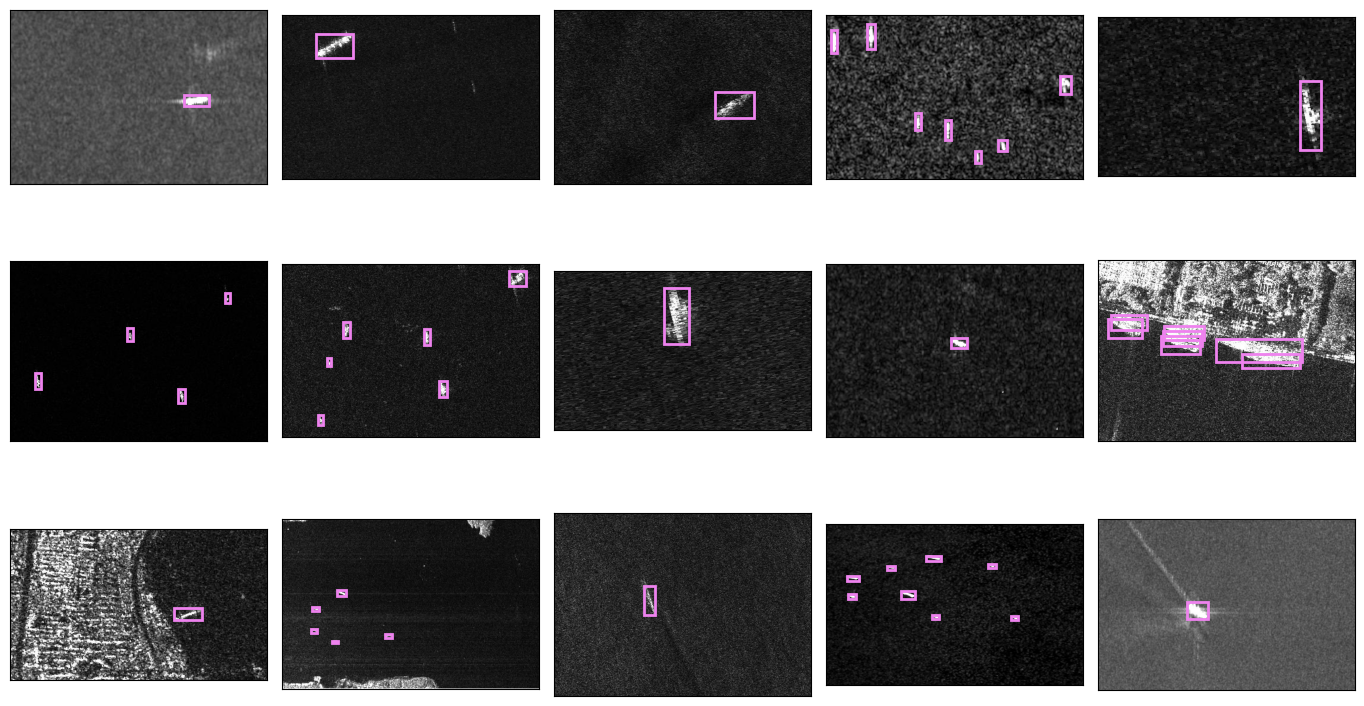

In [11]:
dataset.show_batch(15);

In [19]:
dataset.data_distribution_table()

,Label,Count
0,ship,2587


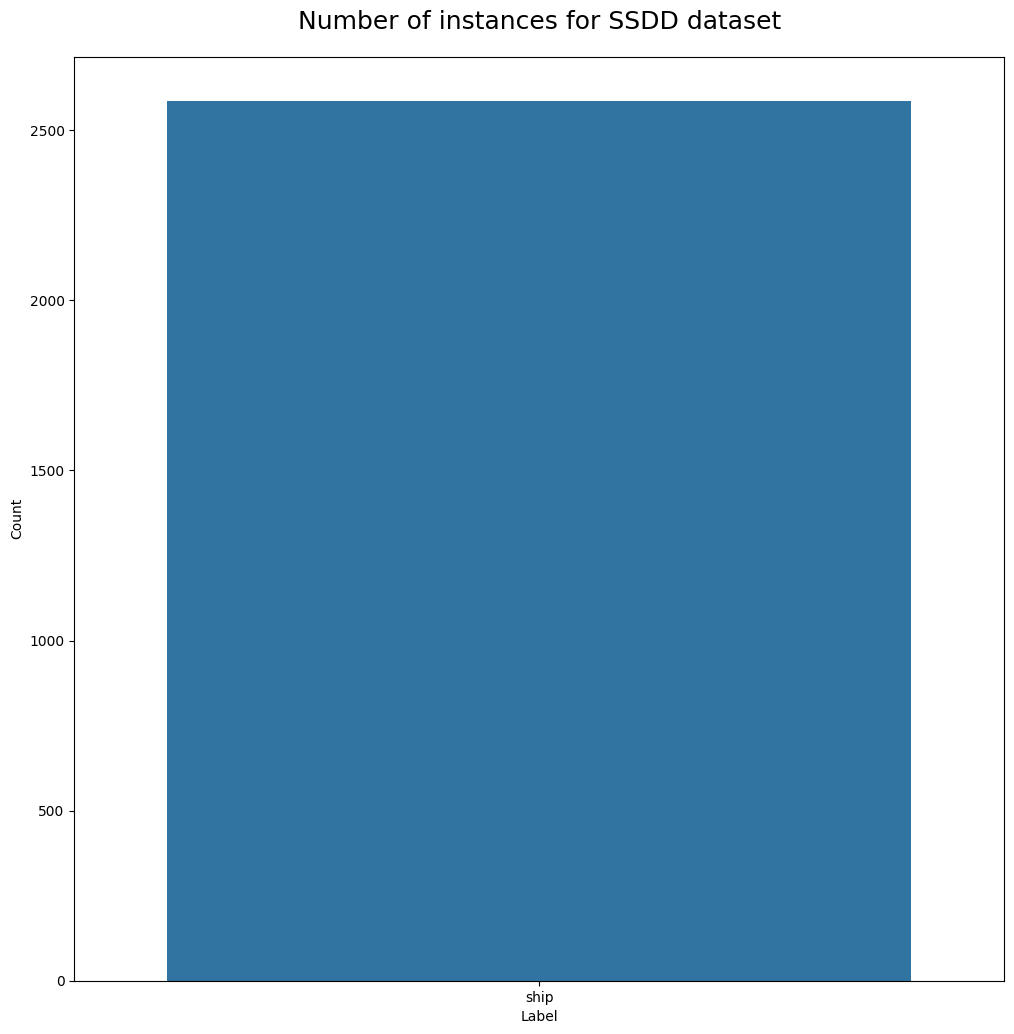

In [13]:
dataset.data_distribution_barchart();

## Load train data

In [5]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "image_dir": "/home/dragik/data/FAIR_EO/SSDD/JPEGImages_train/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/SSDD/Annotations_train/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = SSDDDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 928


## Create the model

In [6]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/SSDD/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-22 09:47:00,190 INFO Starting training.
training: 100%|██████████| 116/116 [00:38<00:00,  3.03it/s]
2025-05-22 09:47:38,925 INFO epoch: 1, time: 38, loss:  0.18826
testing on train set: 100%|██████████| 116/116 [00:25<00:00,  4.56it/s]
2025-05-22 09:48:06,921 INFO map:0.6795744895935059, map_50:0.9659436941146851, map_75:0.8516892194747925, map_small:0.6639715433120728, map_medium:0.7021244764328003, map_large:0.6996999382972717, mar_1:0.34909358620643616, mar_10:0.7096031308174133, mar_100:0.7391474843025208, mar_small:0.7229070663452148, mar_medium:0.7589595317840576, mar_large:0.746666669845581, map_per_class:0.6795744895935059, mar_100_per_class:0.7391474843025208, classes:1.0
training: 100%|██████████| 116/116 [00:39<00:00,  2.94it/s]
2025-05-22 09:48:46,351 INFO epoch: 2, time: 40, loss:  0.11049
testing on train set: 100%|██████████| 116/116 [00:21<00:00,  5.47it/s]
2025-05-22 09:49:08,940 INFO map:0.7130563855171204, map_50:0.966325044631958, map_75:0.887233555316925, m

## Evaluate the model

In [8]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "image_dir": "/home/dragik/data/FAIR_EO/SSDD/JPEGImages_test/",
    "annotations_dir": "/home/dragik/data/FAIR_EO/SSDD/Annotations_test/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = SSDDDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/SSDD/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 232


2025-05-22 09:57:41,734 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SSDD/experiments/checkpoint.pth.tar
2025-05-22 09:57:42,101 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SSDD/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 29/29 [00:05<00:00,  4.90it/s]


[{'map': 0.6917731761932373,
  'map_50': 0.9574592113494873,
  'map_75': 0.8676412105560303,
  'map_small': 0.6451298594474792,
  'map_medium': 0.7431673407554626,
  'map_large': 0.7234545946121216,
  'mar_1': 0.3371794819831848,
  'mar_10': 0.6976190209388733,
  'mar_100': 0.7344322204589844,
  'mar_small': 0.6936395764350891,
  'mar_medium': 0.7829787135124207,
  'mar_large': 0.7428571581840515,
  'map_per_class': 0.6917731761932373,
  'mar_100_per_class': 0.7344322204589844,
  'classes': 1.0}]

## Predictions

2025-05-22 09:57:50,551 INFO Loading checkpoint /home/dragik/data/FAIR_EO/SSDD/experiments/checkpoint.pth.tar
2025-05-22 09:57:50,900 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/SSDD/experiments/checkpoint.pth.tar at epoch 11


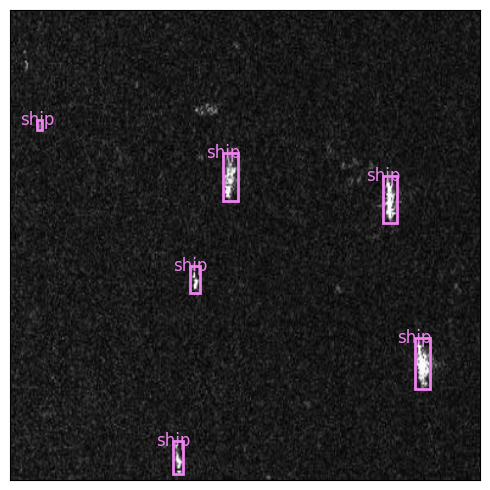

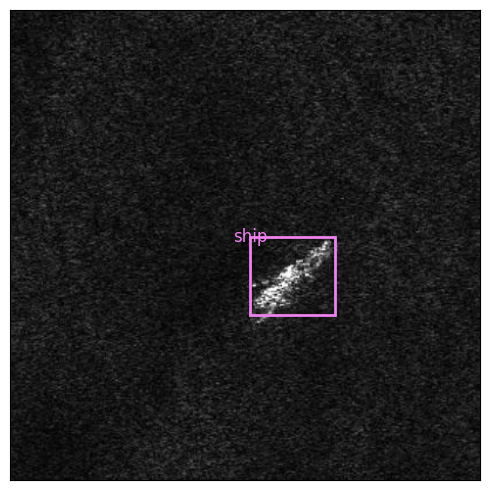

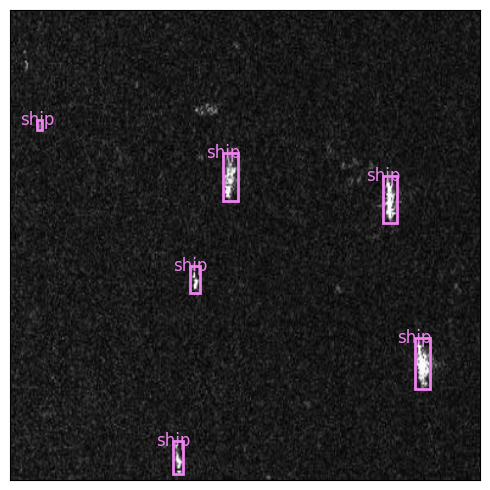

In [9]:
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/SSDD/experiments/checkpoint.pth.tar"
labels = ['no-data','ship']
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/SSDD/JPEGImages_test/000059.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SSDD/JPEGImages_test/000029.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SSDD/JPEGImages_test/000059.jpg')
fig = model.detect_objects(image, labels, transform)